# 5. Deteksi & Inferensi Gambar Uji DOC (*Day-Old Chick*) Sexing
Target Model: **`model_doc_int8.tflite`** | Kategori: **Class 0 (Female)**, **Class 1 (Male)**, dan **Undefined**

Notebook ini melakukan pengujian inferensi lokal menggunakan **TFLite Interpreter INT8** dengan logika keputusan tri-state:
* **Confidence Threshold ($\ge 80\%$)**: Jika tingkat keyakinan model $< 80\%$, status diklasifikasikan sebagai **`undefined` (Ragu-ragu)**.
* **Blank Frame Threshold ($\sigma_{	ext{pixel}} \ge 12.0$)**: Jika citra adalah latar belakang polos atau kosong ($\sigma < 12.0$), status diklasifikasikan sebagai **`undefined` (Frame Kosong)**.
* **Simulasi Aktuator Servo**:
  - `Female (0)` $
ightarrow$ Sudut **`0°`** (Sortir Kiri)
  - `Male (1)` $
ightarrow$ Sudut **`180°`** (Sortir Kanan)
  - `Undefined` $
ightarrow$ Sudut **`90°`** (Center / Standby)


## Langkah 1: Import Library, Konfigurasi Threshold, & Load Model `model_doc_int8.tflite`


In [1]:
import os
import time
import pathlib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Menentukan root direktori proyek PP2 secara otomatis dan portabel
cwd = pathlib.Path.cwd().resolve()
if (cwd / "PP2" / "data").exists():
    PP2_DIR = cwd / "PP2"
elif (cwd / "data").exists():
    PP2_DIR = cwd
elif (cwd.parent / "data").exists():
    PP2_DIR = cwd.parent
else:
    PP2_DIR = cwd
    for p in [cwd] + list(cwd.parents):
        if (p / "PP2" / "data").exists():
            PP2_DIR = p / "PP2"
            break
        elif (p / "data").exists():
            PP2_DIR = p
            break

TFLITE_MODEL_PATH = PP2_DIR / "model" / "model_doc_int8.tflite"
DATA_AUG_DIR = PP2_DIR / "data" / "doc_augmented"
DATA_RAW_DIR = PP2_DIR / "data" / "doc"

# --- KONFIGURASI THRESHOLD DETEKSI UNDEFINED ---
CONFIDENCE_THRESHOLD = 0.80   # Minimal confidence 80% agar diakui sebagai Female atau Male
BLANK_STD_THRESHOLD = 12.0    # Minimal variasi piksel; di bawah ini dianggap frame kosong (undefined)

CLASS_MAP = {
    0: {"code": "0", "name": "Betina (Female)", "servo_angle": 0, "color": "#2ca02c"},
    1: {"code": "1", "name": "Jantan (Male)", "servo_angle": 180, "color": "#d62728"},
    "undefined": {"code": "undefined", "name": "Undefined (Bukan DOC / Kosong / Ragu)", "servo_angle": 90, "color": "#7f7f7f"},
}

if not TFLITE_MODEL_PATH.exists():
    print(f"[WARN] File model {TFLITE_MODEL_PATH} belum ditemukan!")
    print("       Jalankan training terlebih dahulu di Notebook 4 untuk menghasilkan model_doc_int8.tflite.")
else:
    try:
        import tensorflow as tf
        interpreter = tf.lite.Interpreter(model_path=str(TFLITE_MODEL_PATH))
    except ImportError:
        import tflite_runtime.interpreter as tflite
        interpreter = tflite.Interpreter(model_path=str(TFLITE_MODEL_PATH))

    interpreter.allocate_tensors()
    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    IMG_HEIGHT, IMG_WIDTH = input_details["shape"][1], input_details["shape"][2]
    in_scale, in_zero_point = input_details["quantization"]
    out_scale, out_zero_point = output_details["quantization"]

    print(f"[OK] Model berhasil dimuat : {TFLITE_MODEL_PATH.resolve()}")
    print(f"     Resolusi Input Model  : {IMG_WIDTH}x{IMG_HEIGHT} RGB ({input_details['dtype'].__name__})")
    print(f"     Confidence Threshold  : {CONFIDENCE_THRESHOLD * 100:.0f}% (Di bawah ini -> 'undefined')")
    print(f"     Blank Frame Threshold : std < {BLANK_STD_THRESHOLD} (Frame kosong/polos -> 'undefined')")


2026-10-12 00:27:28.710873: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-12 00:27:28.753666: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-12 00:27:28.786754: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-12 00:27:28.786806: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-12 00:27:28.787768: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to

[OK] Model berhasil dimuat : /home/nexus_is/5.Project/Groove-Vision-Ai-v2/PP2/model/model_doc_int8.tflite
     Resolusi Input Model  : 160x160 RGB (int8)
     Confidence Threshold  : 80% (Di bawah ini -> 'undefined')
     Blank Frame Threshold : std < 12.0 (Frame kosong/polos -> 'undefined')


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


## Langkah 2: Fungsi Deteksi Gambar (`detect_doc_sex`)


In [2]:
def detect_doc_sex(
    image_input,
    threshold=CONFIDENCE_THRESHOLD,
    blank_std_threshold=BLANK_STD_THRESHOLD,
    show_plot=True,
):
    # Mendukung input berupa path file maupun objek PIL.Image / numpy array
    if isinstance(image_input, (str, pathlib.Path)):
        image_path = pathlib.Path(image_input)
        if not image_path.exists():
            raise FileNotFoundError(f"Gambar tidak ditemukan: {image_path}")
        orig_img = Image.open(image_path).convert("RGB")
        img_name = image_path.name
    elif isinstance(image_input, Image.Image):
        orig_img = image_input.convert("RGB")
        img_name = "Gambar_Input_Memory"
    else:
        orig_img = Image.fromarray(np.uint8(image_input)).convert("RGB")
        img_name = "Gambar_Array"

    # 1. Ubah ukuran ke resolusi input model (160x160 RGB)
    resized_img = orig_img.resize((IMG_WIDTH, IMG_HEIGHT), Image.Resampling.BILINEAR)
    raw_pixels = np.asarray(resized_img, dtype=np.float32)

    # Cek apakah gambar merupakan frame kosong/polos (variasi piksel sangat rendah)
    pixel_std = float(np.std(raw_pixels))
    is_blank_frame = pixel_std < blank_std_threshold

    # 2. Normalisasi ke [-1.0, 1.0] lalu kuantisasi ke INT8 [-128, 127]
    img_float = (raw_pixels / 127.5) - 1.0
    img_batch = np.expand_dims(img_float, axis=0)

    if input_details["dtype"] == np.int8:
        input_tensor = np.clip(np.round(img_batch / in_scale + in_zero_point), -128, 127).astype(np.int8)
    elif input_details["dtype"] == np.uint8:
        input_tensor = np.clip(np.round(img_batch / in_scale + in_zero_point), 0, 255).astype(np.uint8)
    else:
        input_tensor = img_batch.astype(np.float32)

    # 3. Jalankan Inferensi TFLite
    start_time = time.perf_counter()
    interpreter.set_tensor(input_details["index"], input_tensor)
    interpreter.invoke()
    output_tensor = interpreter.get_tensor(output_details["index"])
    latency_ms = (time.perf_counter() - start_time) * 1000.0

    # 4. Dekuantisasi Output INT8 ke Probabilitas Softmax
    raw_output = output_tensor[0]
    if output_details["dtype"] in (np.int8, np.uint8):
        float_logits = (raw_output.astype(np.float32) - out_zero_point) * out_scale
        exp_logits = np.exp(float_logits - np.max(float_logits))
        probabilities = exp_logits / np.sum(exp_logits)
    else:
        probabilities = raw_output

    prob_female = float(probabilities[0])
    prob_male   = float(probabilities[1])
    raw_max_prob = max(prob_female, prob_male)
    raw_pred_class = int(np.argmax(probabilities))

    # 5. Logika Keputusan 3-State (Dual-Threshold)
    if is_blank_frame:
        final_class = "undefined"
        reason = f"Frame Kosong/Polos (Pixel Std: {pixel_std:.2f} < {blank_std_threshold})"
    elif raw_max_prob < threshold:
        final_class = "undefined"
        reason = f"Confidence Rendah ({raw_max_prob * 100:.1f}% < {threshold * 100:.0f}%)"
    else:
        final_class = raw_pred_class
        reason = f"Klasifikasi Valid ({raw_max_prob * 100:.1f}% >= {threshold * 100:.0f}%)"

    info = CLASS_MAP[final_class]

    result = {
        "image_name": img_name,
        "class_code": info["code"],
        "class_name": info["name"],
        "servo_angle": info["servo_angle"],
        "confidence_female": prob_female,
        "confidence_male": prob_male,
        "max_confidence": raw_max_prob,
        "pixel_std": pixel_std,
        "reason": reason,
        "latency_ms": latency_ms,
    }

    # 6. Visualisasi Hasil
    if show_plot:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1, 1.2]})

        ax1.imshow(orig_img)
        ax1.set_title(f"Input: {img_name}\nStd: {pixel_std:.1f}", fontsize=10)
        ax1.axis("off")

        labels = ["Female (0)", "Male (1)"]
        probs_pct = [prob_female * 100, prob_male * 100]
        bar_colors = ["#2ca02c" if final_class == 0 else "#99d899",
                      "#d62728" if final_class == 1 else "#f4a582"]
        if final_class == "undefined":
            bar_colors = ["#bcbddc", "#bcbddc"]

        y_pos = np.arange(len(labels))
        ax2.barh(y_pos, probs_pct, color=bar_colors, height=0.5, edgecolor="black", linewidth=0.8)
        ax2.axvline(x=threshold * 100, color="blue", linestyle="--", linewidth=1.5, label=f"Ambang Batas ({threshold*100:.0f}%)")
        ax2.set_xlim(0, 105)
        ax2.set_yticks(y_pos)
        ax2.set_yticklabels(labels, fontsize=10, fontweight="bold")
        ax2.set_xlabel("Confidence (%)", fontsize=10)
        ax2.set_title(f"Keputusan: {info['name']}\nServo: {info['servo_angle']}° | {latency_ms:.1f} ms",
                      fontsize=11, fontweight="bold", color=info["color"])
        ax2.legend(loc="lower right", fontsize=8)
        ax2.grid(axis="x", linestyle=":", alpha=0.6)

        for i, v in enumerate(probs_pct):
            ax2.text(v + 1.5, i, f"{v:.1f}%", va="center", fontsize=9, fontweight="bold")

        plt.tight_layout()
        plt.show()

    return result


## Langkah 3: Uji Inferensi Citra Tunggal DOC
Masukkan path gambar uji untuk melihat deteksi jenis kelamin beserta aksi servo.


Menguji Sampel Female: female_test_0001.jpg


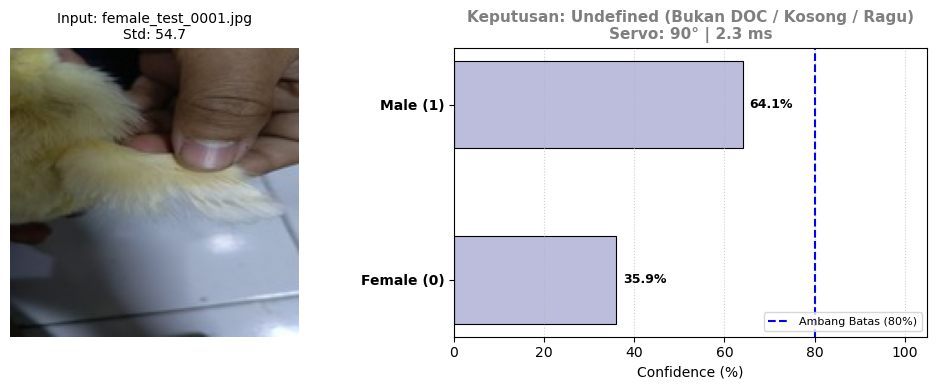

Hasil: {'image_name': 'female_test_0001.jpg', 'class_code': 'undefined', 'class_name': 'Undefined (Bukan DOC / Kosong / Ragu)', 'servo_angle': 90, 'confidence_female': 0.3593641519546509, 'confidence_male': 0.6406359076499939, 'max_confidence': 0.6406359076499939, 'pixel_std': 54.675846099853516, 'reason': 'Confidence Rendah (64.1% < 80%)', 'latency_ms': 2.3005510001894436}


In [3]:
# Contoh memilih citra uji dari folder test
test_female_dir = DATA_AUG_DIR / "test" / "Female"
test_male_dir   = DATA_AUG_DIR / "test" / "Male"

# Fallback ke folder mentah jika belum ada test augmented
if not test_female_dir.exists():
    test_female_dir = DATA_RAW_DIR / "Female"
    test_male_dir   = DATA_RAW_DIR / "Male"

sample_female = sorted(list(test_female_dir.glob("*.jpg")))[0] if list(test_female_dir.glob("*.jpg")) else None
sample_male   = sorted(list(test_male_dir.glob("*.jpg")))[0] if list(test_male_dir.glob("*.jpg")) else None

if sample_female and TFLITE_MODEL_PATH.exists():
    print(f"Menguji Sampel Female: {sample_female.name}")
    res = detect_doc_sex(sample_female)
    print("Hasil:", res)


## Langkah 4: Pengujian Batch / Grid (Female, Male, Blank Frame, & Ambigu)



--- Test Female #1 ---


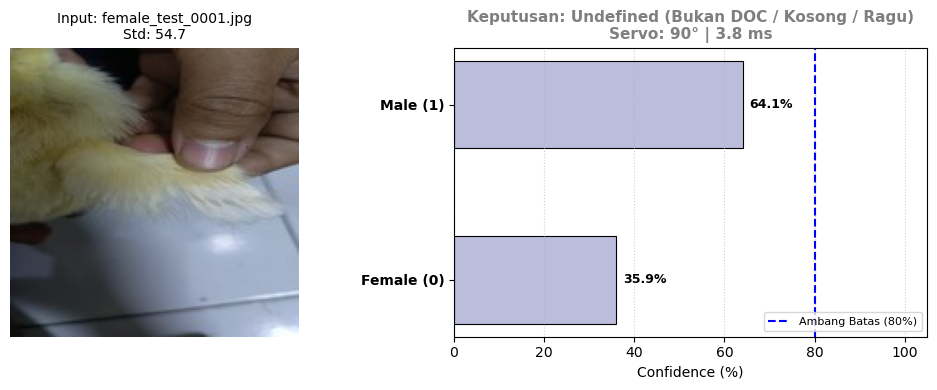


--- Test Male #1 ---


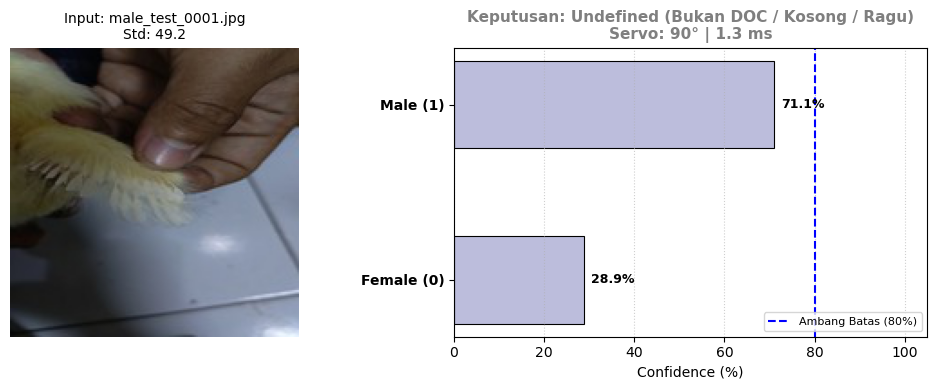


--- Uji Blank Frame ---


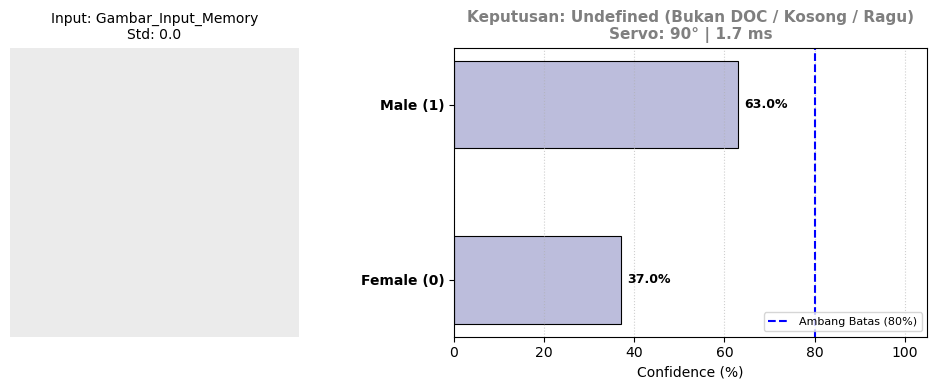


--- Uji Ambigu/Blend ---


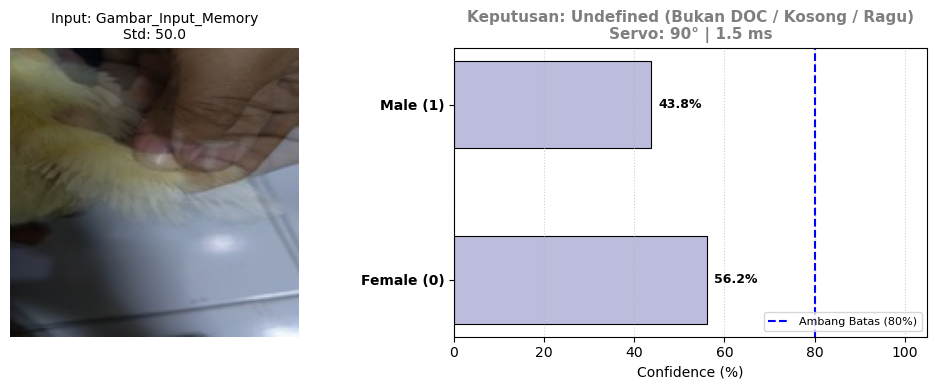

In [4]:
if TFLITE_MODEL_PATH.exists():
    # Ambil 2 sampel Female dan 2 sampel Male
    f_samples = sorted(list(test_female_dir.glob("*.jpg")))[:2]
    m_samples = sorted(list(test_male_dir.glob("*.jpg")))[:2]

    # Buat citra sintetis Blank Frame (tanpa objek, piksel datar)
    blank_img = Image.new("RGB", (160, 160), color=(235, 235, 235))

    # Buat citra sintetis Ambigu (blend 50% Female + 50% Male)
    if f_samples and m_samples:
        im_f = Image.open(f_samples[0]).convert("RGB").resize((160, 160))
        im_m = Image.open(m_samples[0]).convert("RGB").resize((160, 160))
        blend_img = Image.blend(im_f, im_m, alpha=0.5)
    else:
        blend_img = blank_img

    batch_test_items = [
        (f_samples[0], "Test Female #1"),
        (m_samples[0], "Test Male #1"),
        (blank_img,    "Uji Blank Frame"),
        (blend_img,    "Uji Ambigu/Blend")
    ]

    for item, label in batch_test_items:
        print(f"\n--- {label} ---")
        detect_doc_sex(item)
